In [1]:
from pathlib import Path
import torch
import pandas as pd
import matplotlib.pyplot as plt

from src.run.model.run_segment_cnn_classifier import RunSegmentCNN
from src.run.preprocess.config import _project_path


=== Running experiment with window_size=128 ===

FOLD 01/5
Train patients: 57
Validation patients: 15
Fold 01 | Epoch 01 | train_loss=0.6632 | train_accuracy=0.5610 | train_f1=0.6789 | train_auc=0.5701 | train_precision=0.5878 | train_recall=0.8034 | train_specificity=0.2292 | val_loss=0.6568 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.8036 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6342 | train_accuracy=0.5922 | train_f1=0.6938 | train_auc=0.6296 | train_precision=0.6127 | train_recall=0.7995 | train_specificity=0.3087 | val_loss=0.6613 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.6964 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 03 | train_loss=0.6404 | train_accuracy=0.5953 | train_f1=0.6900 | train_auc=0.6202 | train_precision=0.6188 | train_recall=0.7797 | train_specificity=0.3430 | val_loss=0.6576 | val_accuracy=0.5333 | val_f1=0.2222 | val_auc=0.6250 | val_precision=1.00

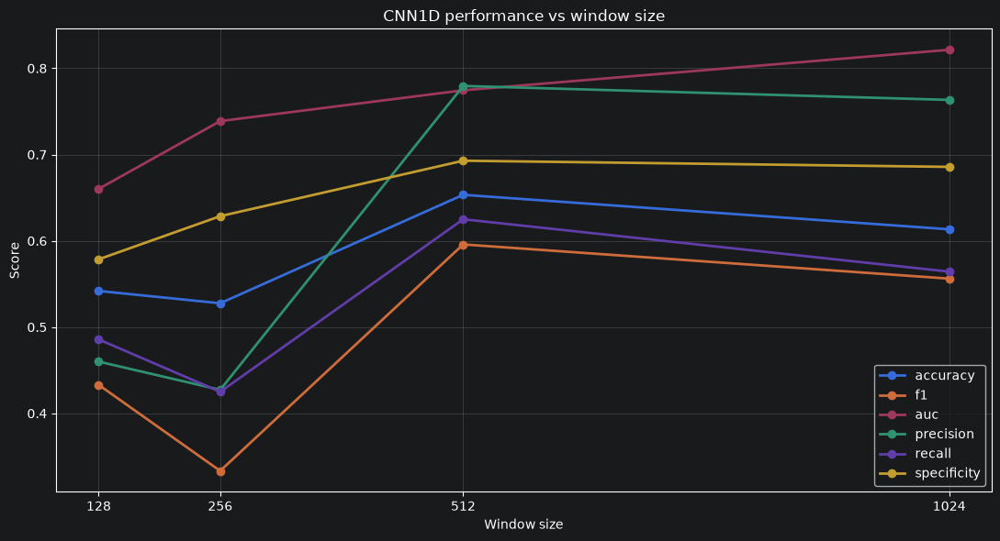

In [2]:
# WINDOW SIZE

window_sizes = [128, 256, 512, 1024]
results = []

for w in window_sizes:

    print(f"\n=== Running experiment with window_size={w} ===")

    runner = RunSegmentCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
        tasks=[1],
        feature_names=("x", "y"),
        engineered_features=(),
        window_size=w,
        epochs=50,
        batch_size=32,
        learning_rate=1e-3,
        n_splits=5,
        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",
        aggregation="mean",
        output_dir=_project_path(f"experiments/test_iperparametri/cnn1D(train seg - val no)/window_size/w_{w}"),
        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],
            "monitor_metric": "auc",
            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,
            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "window_size": w,
    }

    row.update(summary["averages"])
    results.append(row)

df = pd.DataFrame(results).sort_values("window_size")

print("\n=== Summary ===")
print(df)

# Plot
metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:
    plt.plot(
        df["window_size"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(df["window_size"])

plt.xlabel("Window size")
plt.ylabel("Score")
plt.title("CNN1D performance vs window size")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()


=== Running experiment with epochs=25 ===

FOLD 01/5
Train patients: 57
Validation patients: 15
Fold 01 | Epoch 01 | train_loss=0.6709 | train_accuracy=0.6160 | train_f1=0.6700 | train_auc=0.6013 | train_precision=0.6634 | train_recall=0.6766 | train_specificity=0.5338 | val_loss=0.6887 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.5893 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6480 | train_accuracy=0.6160 | train_f1=0.6869 | train_auc=0.6520 | train_precision=0.6476 | train_recall=0.7313 | train_specificity=0.4595 | val_loss=0.6980 | val_accuracy=0.5333 | val_f1=0.2222 | val_auc=0.4821 | val_precision=1.0000 | val_recall=0.1250 | val_specificity=1.0000
Fold 01 | Epoch 03 | train_loss=0.6155 | train_accuracy=0.6504 | train_f1=0.7215 | train_auc=0.7028 | train_precision=0.6667 | train_recall=0.7861 | train_specificity=0.4662 | val_loss=0.6596 | val_accuracy=0.5333 | val_f1=0.2222 | val_auc=0.5714 | val_precision=1.0000 | v

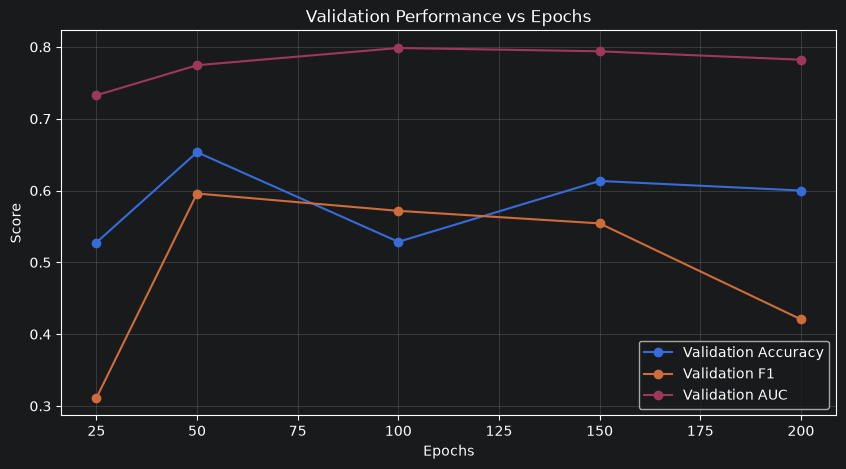

In [4]:
# EPOCHS

results = []

epochs_list = [25, 50, 100, 150, 200]

for e in epochs_list:

    print(f"\n=== Running experiment with epochs={e} ===")

    runner = RunSegmentCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
        tasks=[1],
        feature_names=("x", "y"),
        engineered_features=(),
        window_size=512,
        epochs=e,
        batch_size=32,
        learning_rate=1e-3,
        n_splits=5,
        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",
        aggregation="mean",
        output_dir=_project_path(f"experiments/test_iperparametri/cnn1D(train seg - val no)/epochs/e_{e}"),
        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],
            "monitor_metric": "auc",
            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,
            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {"epochs": e}
    row.update(summary["averages"])
    results.append(row)

df = pd.DataFrame(results).sort_values("epochs")

print("\n=== Summary ===")
print(df)

# Plot
plt.figure(figsize=(10, 5))

plt.plot(
    df["epochs"],
    df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.plot(
    df["epochs"],
    df["val_f1"],
    marker="o",
    label="Validation F1"
)

plt.plot(
    df["epochs"],
    df["val_auc"],
    marker="o",
    label="Validation AUC"
)

plt.xlabel("Epochs")
plt.ylabel("Score")
plt.title("Validation Performance vs Epochs")
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()


=== Running experiment with lr=0.01 ===

FOLD 01/5
Train patients: 57
Validation patients: 15
Fold 01 | Epoch 01 | train_loss=1.0525 | train_accuracy=0.5358 | train_f1=0.6049 | train_auc=0.4948 | train_precision=0.5933 | train_recall=0.6169 | train_specificity=0.4257 | val_loss=0.6967 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.4643 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6776 | train_accuracy=0.5788 | train_f1=0.7101 | train_auc=0.5760 | train_precision=0.5882 | train_recall=0.8955 | train_specificity=0.1486 | val_loss=0.6946 | val_accuracy=0.4000 | val_f1=0.4706 | val_auc=0.4643 | val_precision=0.4444 | val_recall=0.5000 | val_specificity=0.2857
Fold 01 | Epoch 03 | train_loss=0.6411 | train_accuracy=0.6074 | train_f1=0.7187 | train_auc=0.6487 | train_precision=0.6119 | train_recall=0.8706 | train_specificity=0.2500 | val_loss=0.6686 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.4643 | val_precision=0.5333 | val

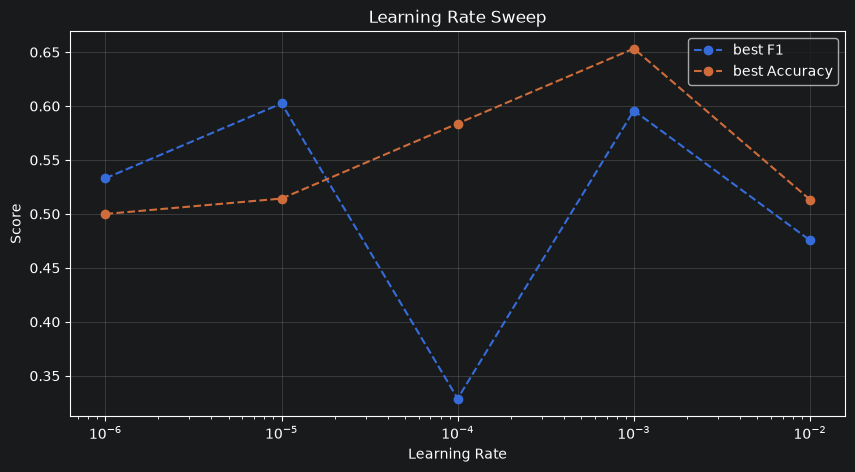

In [5]:
# LEARNING RATE
results = []

lrs = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]

for lr in lrs:

    print(f"\n=== Running experiment with lr={lr} ===")

    runner = RunSegmentCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
        tasks=[1],
        feature_names=("x", "y"),
        engineered_features=(),
        window_size=512,
        epochs= 50,
        batch_size=32,
        learning_rate=lr,
        n_splits=5,
        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",
        aggregation="mean",
        output_dir=_project_path(f"experiments/test_iperparametri/cnn1D(train seg - val no)/learning_rate/lr_{lr}"),
        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],
            "monitor_metric": "auc",
            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,
            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {"learning_rate": lr}
    row.update(summary["averages"])
    results.append(row)

df = pd.DataFrame(results).sort_values("learning_rate")

print("\n=== Summary ===")
print(df)

# Plot
plt.figure(figsize=(10, 5))

# BEST
plt.plot(
    df["learning_rate"],
    df["val_f1"],
    marker="o",
    linestyle="--",
    label="best F1"
)

plt.plot(
    df["learning_rate"],
    df["val_accuracy"],
    marker="o",
    linestyle="--",
    label="best Accuracy"
)

plt.xscale("log")

plt.xlabel("Learning Rate")
plt.ylabel("Score")
plt.title("Learning Rate Sweep")

plt.grid(True, alpha=0.3)
plt.legend()

plt.show()


=== Summary ===
   learning_rate  train_loss  val_loss  train_accuracy  val_accuracy  \
4       0.000001    0.680519  0.699575        0.563198      0.500000   
3       0.000010    0.634926  0.683433        0.614067      0.514286   
2       0.000100    0.548391  0.683974        0.695461      0.583810   
1       0.001000    0.525088  0.722941        0.683709      0.653333   
0       0.010000    0.612581  0.697814        0.610984      0.513333   

   train_f1    val_f1  train_auc   val_auc  train_precision  val_precision  \
4  0.630263  0.533070   0.543183  0.451531         0.578740       0.400000   
3  0.683901  0.602427   0.680442  0.566327         0.628506       0.511111   
2  0.711750  0.328889   0.758614  0.706122         0.735574       0.666667   
1  0.699857  0.595846   0.746244  0.774490         0.719214       0.779524   
0  0.676055  0.475606   0.655414  0.772449         0.651161       0.585000   

   train_recall  val_recall  train_specificity  val_specificity  
4      0.753424

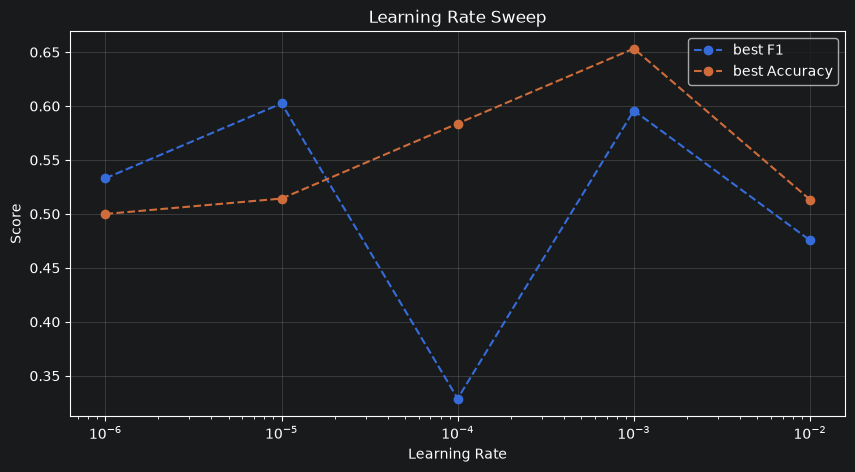

In [6]:
df = pd.DataFrame(results).sort_values("learning_rate")

print("\n=== Summary ===")
print(df)

# Plot
plt.figure(figsize=(10, 5))

# BEST
plt.plot(
    df["learning_rate"],
    df["val_f1"],
    marker="o",
    linestyle="--",
    label="best F1"
)

plt.plot(
    df["learning_rate"],
    df["val_accuracy"],
    marker="o",
    linestyle="--",
    label="best Accuracy"
)

plt.xscale("log")

plt.xlabel("Learning Rate")
plt.ylabel("Score")
plt.title("Learning Rate Sweep")

plt.grid(True, alpha=0.3)
plt.legend()

plt.show()


=== Running experiment with regularization=1e-08 ===

FOLD 01/5
Train patients: 57
Validation patients: 15
Fold 01 | Epoch 01 | train_loss=0.6708 | train_accuracy=0.6189 | train_f1=0.6716 | train_auc=0.6013 | train_precision=0.6667 | train_recall=0.6766 | train_specificity=0.5405 | val_loss=0.6886 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.5536 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6479 | train_accuracy=0.6160 | train_f1=0.6869 | train_auc=0.6515 | train_precision=0.6476 | train_recall=0.7313 | train_specificity=0.4595 | val_loss=0.6983 | val_accuracy=0.5333 | val_f1=0.2222 | val_auc=0.4821 | val_precision=1.0000 | val_recall=0.1250 | val_specificity=1.0000
Fold 01 | Epoch 03 | train_loss=0.6151 | train_accuracy=0.6533 | train_f1=0.7231 | train_auc=0.7026 | train_precision=0.6695 | train_recall=0.7861 | train_specificity=0.4730 | val_loss=0.6597 | val_accuracy=0.5333 | val_f1=0.2222 | val_auc=0.5714 | val_precision

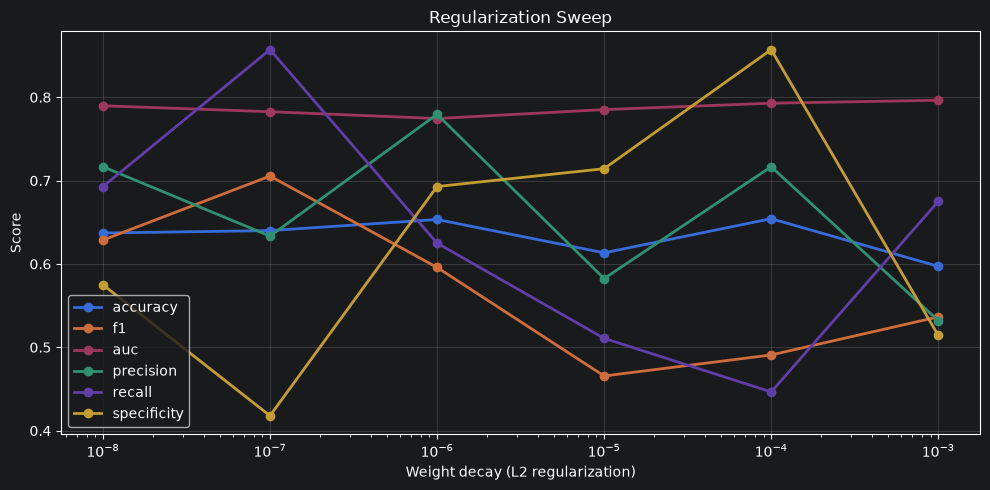

In [7]:
# REGULARIZATION

results = []

regs = [1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3]

for reg in regs:

    print(f"\n=== Running experiment with regularization={reg} ===")

    runner = RunSegmentCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
        tasks=[1],
        feature_names=("x", "y"),
        engineered_features=(),
        window_size=512,
        epochs=50,
        batch_size=32,
        learning_rate=1e-3,
        regularization=reg,
        n_splits=5,
        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",
        aggregation="mean",
        output_dir=_project_path(f"experiments/test_iperparametri/cnn1D(train seg - val no)/regularization/reg_{reg}"),
        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],
            "monitor_metric": "auc",
            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,
            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {"regularization": reg}
    row.update(summary["averages"])

    results.append(row)

df = pd.DataFrame(results).sort_values("regularization")

print("\n=== Summary ===")
print(df)

# Plot

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(10, 5))

for metric in metrics:
    plt.plot(
        df["regularization"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xscale("log")

plt.xlabel("Weight decay (L2 regularization)")
plt.ylabel("Score")
plt.title("Regularization Sweep")

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


=== Running experiment with batch_size=16 ===

FOLD 01/5
Train patients: 57
Validation patients: 15
Fold 01 | Epoch 01 | train_loss=0.6723 | train_accuracy=0.5645 | train_f1=0.6381 | train_auc=0.5890 | train_precision=0.6119 | train_recall=0.6667 | train_specificity=0.4257 | val_loss=0.7181 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.5179 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6425 | train_accuracy=0.5960 | train_f1=0.6698 | train_auc=0.6511 | train_precision=0.6327 | train_recall=0.7114 | train_specificity=0.4392 | val_loss=0.6747 | val_accuracy=0.4667 | val_f1=0.6000 | val_auc=0.4821 | val_precision=0.5000 | val_recall=0.7500 | val_specificity=0.1429
Fold 01 | Epoch 03 | train_loss=0.6253 | train_accuracy=0.6361 | train_f1=0.7107 | train_auc=0.6780 | train_precision=0.6555 | train_recall=0.7761 | train_specificity=0.4459 | val_loss=0.6622 | val_accuracy=0.6000 | val_f1=0.5000 | val_auc=0.5179 | val_precision=0.7500

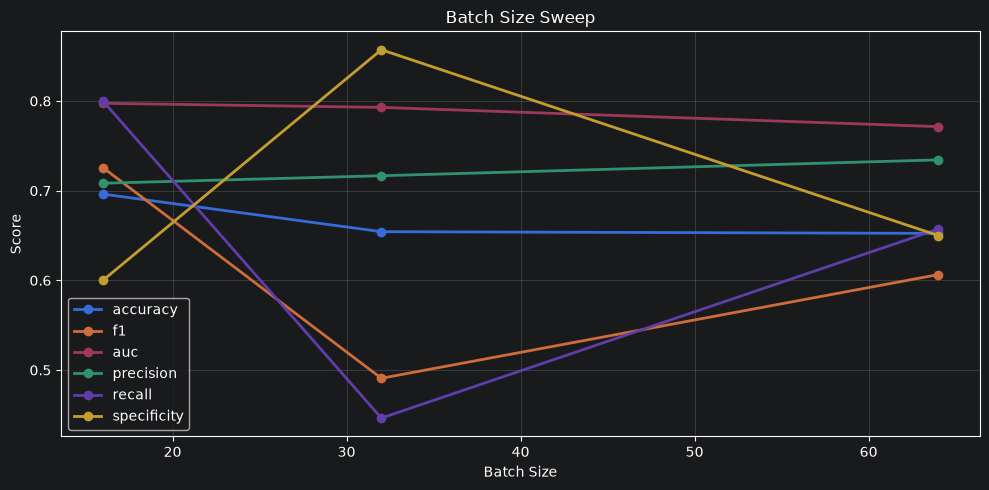

In [9]:
# BATCH SIZE
results = []

batch_size = [16, 32, 64]

for batch in batch_size:

    print(f"\n=== Running experiment with batch_size={batch} ===")

    runner = RunSegmentCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
        tasks=[1],
        feature_names=("x", "y"),
        engineered_features=(),
        window_size=512,
        epochs=50,
        batch_size=batch,
        learning_rate=1e-3,
        regularization=1e-4,
        n_splits=5,
        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",
        aggregation="mean",
        output_dir=_project_path(
            f"experiments/test_iperparametri/cnn1D(train seg - val no)/batch_size/size_{batch}"
        ),
        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],
            "monitor_metric": "auc",
            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,
            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {"batch": batch}
    row.update(summary["averages"])

    results.append(row)

df = pd.DataFrame(results).sort_values("batch")

print("\n=== Summary ===")
print(df)

# Plot

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(10, 5))

for metric in metrics:
    plt.plot(
        df["batch"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xlabel("Batch Size")
plt.ylabel("Score")
plt.title("Batch Size Sweep")

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


=== Running experiment with early_stopping=5 ===

FOLD 01/5
Train patients: 57
Validation patients: 15
Fold 01 | Epoch 01 | train_loss=0.6723 | train_accuracy=0.5645 | train_f1=0.6381 | train_auc=0.5890 | train_precision=0.6119 | train_recall=0.6667 | train_specificity=0.4257 | val_loss=0.7181 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.5179 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6425 | train_accuracy=0.5960 | train_f1=0.6698 | train_auc=0.6511 | train_precision=0.6327 | train_recall=0.7114 | train_specificity=0.4392 | val_loss=0.6747 | val_accuracy=0.4667 | val_f1=0.6000 | val_auc=0.4821 | val_precision=0.5000 | val_recall=0.7500 | val_specificity=0.1429
Fold 01 | Epoch 03 | train_loss=0.6253 | train_accuracy=0.6361 | train_f1=0.7107 | train_auc=0.6780 | train_precision=0.6555 | train_recall=0.7761 | train_specificity=0.4459 | val_loss=0.6622 | val_accuracy=0.6000 | val_f1=0.5000 | val_auc=0.5179 | val_precision=0.7

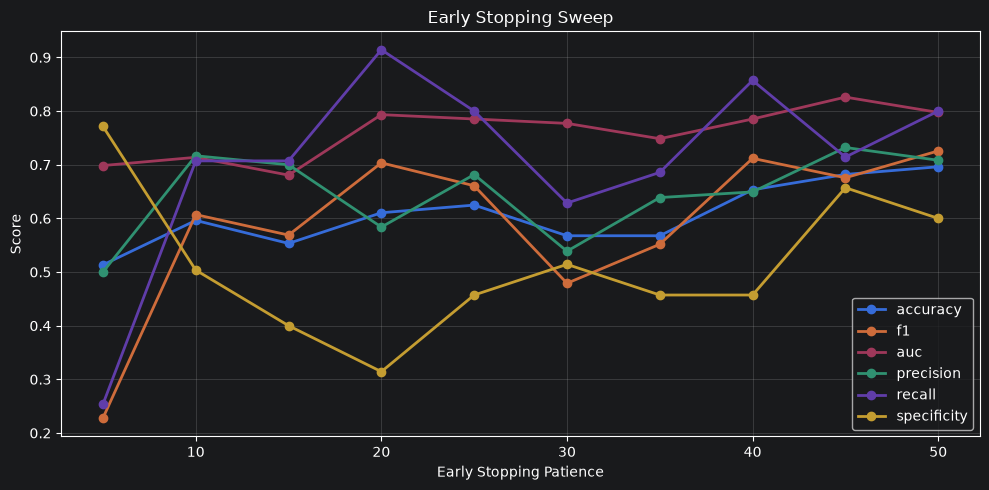

In [10]:
# EARLY STOPPING
results = []

early_stops = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]

for patience in early_stops:

    print(f"\n=== Running experiment with early_stopping={patience} ===")

    runner = RunSegmentCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
        tasks=[1],
        feature_names=("x", "y"),
        engineered_features=(),
        window_size=512,
        epochs=50,
        batch_size=16,
        learning_rate=1e-3,
        regularization=1e-4,
        n_splits=5,
        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",
        aggregation="mean",
        output_dir=_project_path(
            f"experiments/test_iperparametri/cnn1D(train seg - val no)/early_stopping/patience_{patience}"
        ),
        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],
            "monitor_metric": "auc",
            "early_stopping_patience": patience,
            "min_delta": 1e-3,
            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {"patience": patience}
    row.update(summary["averages"])

    results.append(row)

df = pd.DataFrame(results).sort_values("patience")

print("\n=== Summary ===")
print(df)

# Plot

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(10, 5))

for metric in metrics:
    plt.plot(
        df["patience"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xlabel("Early Stopping Patience")
plt.ylabel("Score")
plt.title("Early Stopping Sweep")

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


=== Running experiment with min_delta=0.0 ===

FOLD 01/5
Train patients: 57
Validation patients: 15
Fold 01 | Epoch 01 | train_loss=0.6723 | train_accuracy=0.5645 | train_f1=0.6381 | train_auc=0.5890 | train_precision=0.6119 | train_recall=0.6667 | train_specificity=0.4257 | val_loss=0.7181 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.5179 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6425 | train_accuracy=0.5960 | train_f1=0.6698 | train_auc=0.6511 | train_precision=0.6327 | train_recall=0.7114 | train_specificity=0.4392 | val_loss=0.6747 | val_accuracy=0.4667 | val_f1=0.6000 | val_auc=0.4821 | val_precision=0.5000 | val_recall=0.7500 | val_specificity=0.1429
Fold 01 | Epoch 03 | train_loss=0.6253 | train_accuracy=0.6361 | train_f1=0.7107 | train_auc=0.6780 | train_precision=0.6555 | train_recall=0.7761 | train_specificity=0.4459 | val_loss=0.6622 | val_accuracy=0.6000 | val_f1=0.5000 | val_auc=0.5179 | val_precision=0.7500

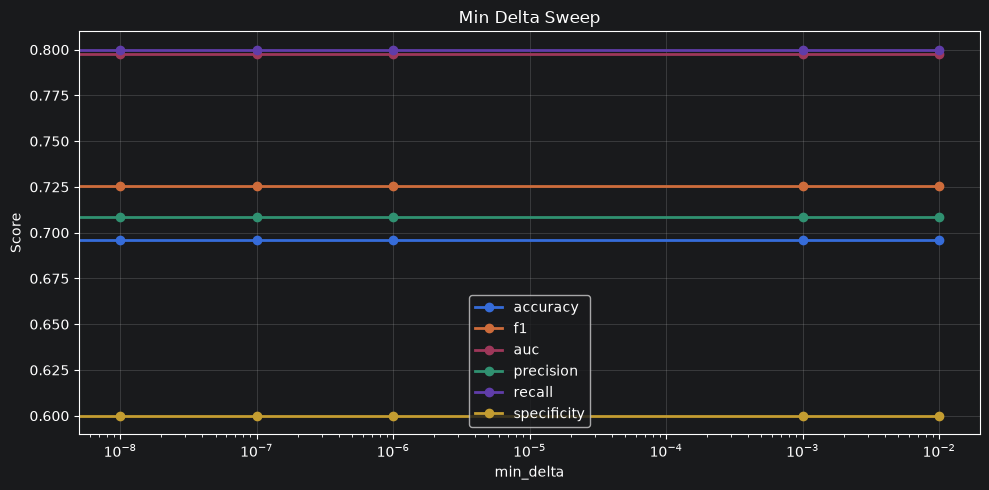

In [11]:
# MIN_DELTA
results = []

min_delta = [0.0, 1e-2, 1e-3, 1e-6, 1e-7, 1e-8]

for delta in min_delta:

    print(f"\n=== Running experiment with min_delta={delta} ===")

    runner = RunSegmentCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
        tasks=[1],
        feature_names=("x", "y"),
        engineered_features=(),
        window_size=512,
        epochs=50,
        batch_size=16,
        learning_rate=1e-3,
        regularization=1e-4,
        n_splits=5,
        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",
        aggregation="mean",
        output_dir=_project_path(
            f"experiments/test_iperparametri/cnn1D(train seg - val no)/min_delta/delta_{delta}"
        ),
        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],
            "monitor_metric": "auc",
            "early_stopping_patience": 50,
            "min_delta": delta,
            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {"min_delta": delta}
    row.update(summary["averages"])

    results.append(row)

df = pd.DataFrame(results).sort_values("min_delta")

print("\n=== Summary ===")
print(df)

# Plot

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(10, 5))

for metric in metrics:
    plt.plot(
        df["min_delta"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xscale("log")
plt.xlabel("min_delta")
plt.ylabel("Score")
plt.title("Min Delta Sweep")

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


FOLD 01/5
Train patients: 57
Validation patients: 15
Fold 01 | Epoch 01 | train_loss=0.6703 | train_accuracy=0.5874 | train_f1=0.6814 | train_auc=0.5811 | train_precision=0.6135 | train_recall=0.7662 | train_specificity=0.3446 | val_loss=0.7025 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.6071 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6318 | train_accuracy=0.5931 | train_f1=0.6787 | train_auc=0.6590 | train_precision=0.6224 | train_recall=0.7463 | train_specificity=0.3851 | val_loss=0.6413 | val_accuracy=0.5333 | val_f1=0.4615 | val_auc=0.6071 | val_precision=0.6000 | val_recall=0.3750 | val_specificity=0.7143
Fold 01 | Epoch 03 | train_loss=0.6233 | train_accuracy=0.6275 | train_f1=0.6829 | train_auc=0.6831 | train_precision=0.6699 | train_recall=0.6965 | train_specificity=0.5338 | val_loss=0.6705 | val_accuracy=0.5333 | val_f1=0.2222 | val_auc=0.5357 | val_precision=1.0000 | val_recall=0.1250 | val_specificity=1.0000
F

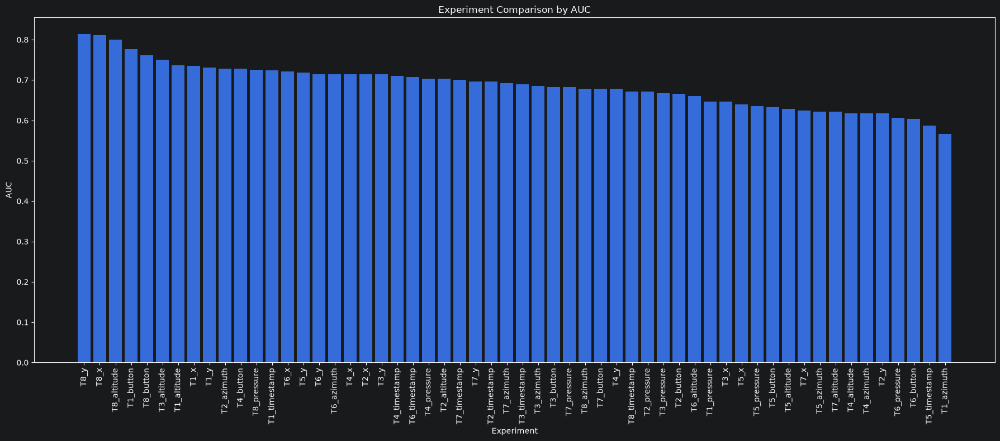

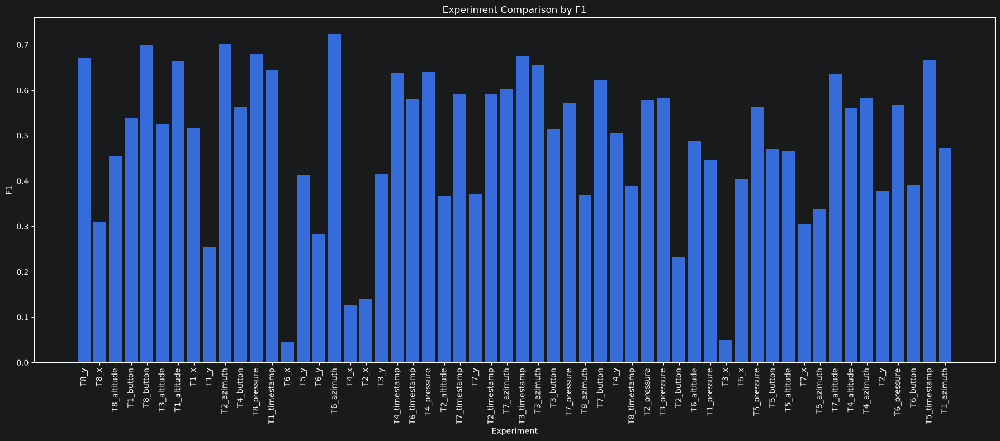

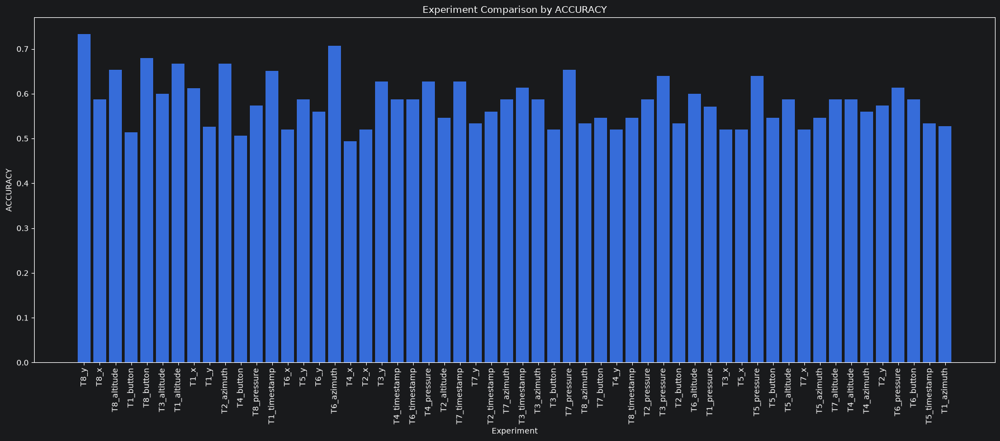

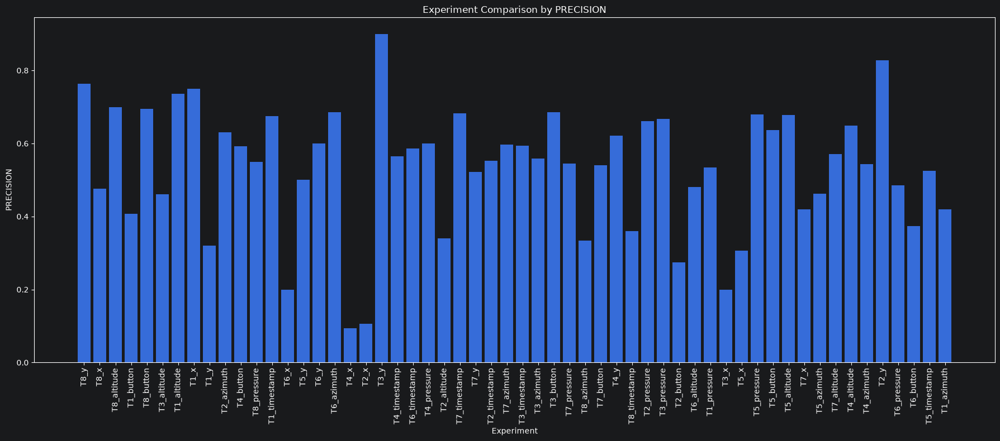

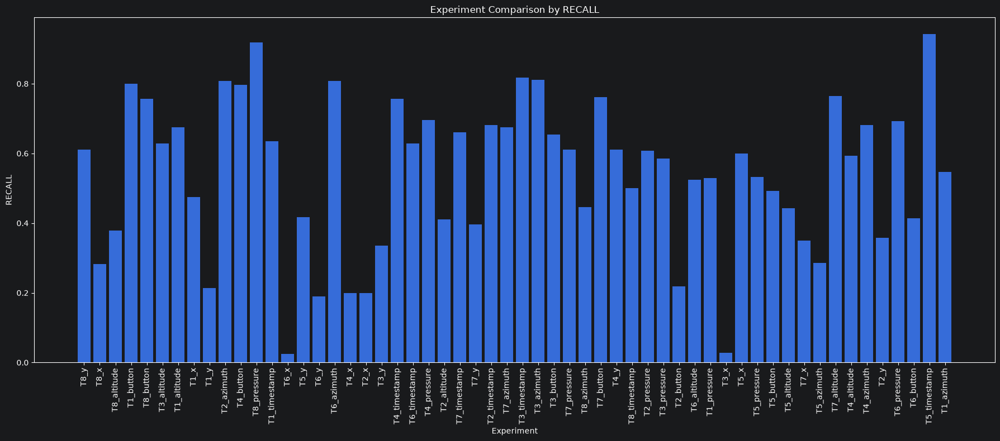


=== BEST EXPERIMENT ===
Task: 8
Feature: y
AUC: 0.8143
F1: 0.6713
Accuracy: 0.7333


In [15]:
# Experiments for cnn1D (one feature -> one task)

features = ["x", "y", "button", "timestamp", "azimuth", "altitude", "pressure"]
tasks = [1, 2, 3, 4, 5, 6, 7, 8]
results = []

for t in tasks:
    for f in features:
        if f == "x" or f == "y":

            runner = RunSegmentCNN(
                    data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
                    metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
                    tasks=[t],
                    feature_names=(f,),
                    engineered_features=(),
                    window_size=512,
                    epochs=50,
                    batch_size=16,
                    learning_rate=1e-3,
                    regularization=1e-4,
                    n_splits=5,
                    normalize=True,
                    device="cuda" if torch.cuda.is_available() else "cpu",
                    aggregation="mean",
                    output_dir=_project_path(f"experiments/cnn1D/raw_segment(train_seg - val_no)/Task_{t}/{f}_coordinate"),
                    training_cfg={
                        "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
                        "monitor_metric": "auc",
                        "early_stopping_patience": 50,
                        "min_delta": 0.0,
                        "results_writer": "csv",
                        "save_metrics": True,
                    }
                )
        else:
            runner = RunSegmentCNN(
                    data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
                    metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
                    tasks=[t],
                    feature_names=(f,),
                    engineered_features=(),
                    window_size=512,
                    epochs=50,
                    batch_size=16,
                    learning_rate=1e-3,
                    regularization=1e-4,
                    n_splits=5,
                    normalize=True,
                    device="cuda" if torch.cuda.is_available() else "cpu",
                    aggregation="mean",
                    output_dir=_project_path(f"experiments/cnn1D/raw_segment(train_seg - val_no)/Task_{t}/{f}"),
                    training_cfg={
                        "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
                        "monitor_metric": "auc",
                        "early_stopping_patience": 50,
                        "min_delta": 0.0,
                        "results_writer": "csv",
                        "save_metrics": True,
                    }
                )

        summary = runner.run()

        averages = summary["averages"]

        results.append({
            "task": t,
            "feature": f,
            "accuracy": averages["val_accuracy"],
            "f1": averages["val_f1"],
            "auc": averages["val_auc"],
            "precision": averages["val_precision"],
            "recall": averages["val_recall"],
            "specificity": averages["val_specificity"],
        })

# =========================
# DATAFRAME
# =========================

df = pd.DataFrame(results)

# Ordina per AUC
df_sorted = df.sort_values(by="auc", ascending=False)

print("\n=== TOP EXPERIMENTS ===")
print(df_sorted.head(10))

# =========================
# PLOT AUC
# =========================

labels = [
    f"T{row.task}_{row.feature}"
    for row in df_sorted.itertuples()
]

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["auc"])

plt.xticks(rotation=90)
plt.ylabel("AUC")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by AUC")

plt.tight_layout()
plt.show()

# =========================
# PLOT F1
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["f1"])

plt.xticks(rotation=90)
plt.ylabel("F1")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by F1")

plt.tight_layout()
plt.show()

# =========================
# PLOT ACCURACY
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["accuracy"])

plt.xticks(rotation=90)
plt.ylabel("ACCURACY")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by ACCURACY")

plt.tight_layout()
plt.show()

# =========================
# PLOT PRECISION
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["precision"])

plt.xticks(rotation=90)
plt.ylabel("PRECISION")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by PRECISION")

plt.tight_layout()
plt.show()

# =========================
# PLOT RECALL
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["recall"])

plt.xticks(rotation=90)
plt.ylabel("RECALL")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by RECALL")

plt.tight_layout()
plt.show()

# =========================
# BEST EXPERIMENT
# =========================

best = df_sorted.iloc[0]

print("\n=== BEST EXPERIMENT ===")
print(f"Task: {best['task']}")
print(f"Feature: {best['feature']}")
print(f"AUC: {best['auc']:.4f}")
print(f"F1: {best['f1']:.4f}")
print(f"Accuracy: {best['accuracy']:.4f}")

In [22]:
# Experiments for cnn1D with engineering features

features = ["speed", "acceleration", "velocity", "pressure_derivative"]
task = [1, 2, 3, 4, 5, 6, 7, 8]
results = []

for t in task:
    for f in features:

        runner = RunSegmentCNN(
                data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
                metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
                tasks=[t],
                feature_names=(),
                engineered_features=(f,),
                window_size=512,
                epochs=50,
                batch_size=16,
                learning_rate=1e-3,
                regularization=1e-4,
                n_splits=5,
                normalize=True,
                device="cuda" if torch.cuda.is_available() else "cpu",
                aggregation="mean",
                output_dir=_project_path(f"experiments/cnn1D/raw_segment(train_seg - val_no)/Task_{t}/{f}"),
                training_cfg={
                    "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
                    "monitor_metric": "auc",
                    "early_stopping_patience": 50,
                    "min_delta": 0.0,
                    "results_writer": "csv",
                    "save_metrics": True,
                }
            )

        summary = runner.run()

        averages = summary["averages"]

        results.append({
            "task": t,
            "feature": f,
            "accuracy": averages["val_accuracy"],
            "f1": averages["val_f1"],
            "auc": averages["val_auc"],
            "precision": averages["val_precision"],
            "recall": averages["val_recall"],
            "specificity": averages["val_specificity"],
        })

# =========================
# DATAFRAME
# =========================

df = pd.DataFrame(results)

# Ordina per AUC
df_sorted = df.sort_values(by="auc", ascending=False)

print("\n=== TOP EXPERIMENTS ===")
print(df_sorted.head(10))

# =========================
# PLOT AUC
# =========================

labels = [
    f"T{row.task}_{row.feature}"
    for row in df_sorted.itertuples()
]

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["auc"])

plt.xticks(rotation=90)
plt.ylabel("AUC")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by AUC")

plt.tight_layout()
plt.show()

# =========================
# PLOT F1
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["f1"])

plt.xticks(rotation=90)
plt.ylabel("F1")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by F1")

plt.tight_layout()
plt.show()

# =========================
# BEST EXPERIMENT
# =========================

best = df_sorted.iloc[0]

print("\n=== BEST EXPERIMENT ===")
print(f"Task: {best['task']}")
print(f"Feature: {best['feature']}")
print(f"AUC: {best['auc']:.4f}")
print(f"F1: {best['f1']:.4f}")
print(f"Accuracy: {best['accuracy']:.4f}")


FOLD 01/5
Train patients: 57
Validation patients: 15
Fold 01 | Epoch 01 | train_loss=0.6696 | train_accuracy=0.5960 | train_f1=0.6831 | train_auc=0.6024 | train_precision=0.6230 | train_recall=0.7562 | train_specificity=0.3784 | val_loss=0.7461 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.5357 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6356 | train_accuracy=0.5960 | train_f1=0.6635 | train_auc=0.6566 | train_precision=0.6376 | train_recall=0.6915 | train_specificity=0.4662 | val_loss=0.7414 | val_accuracy=0.5333 | val_f1=0.5333 | val_auc=0.5000 | val_precision=0.5714 | val_recall=0.5000 | val_specificity=0.5714
Fold 01 | Epoch 03 | train_loss=0.5906 | train_accuracy=0.6562 | train_f1=0.6859 | train_auc=0.7103 | train_precision=0.7238 | train_recall=0.6517 | train_specificity=0.6622 | val_loss=0.7467 | val_accuracy=0.4667 | val_f1=0.4286 | val_auc=0.4107 | val_precision=0.5000 | val_recall=0.3750 | val_specificity=0.5714
F

Fold 02 | Epoch 35 | train_loss=0.4350 | train_accuracy=0.7642 | train_f1=0.7738 | train_auc=0.8603 | train_precision=0.8712 | train_recall=0.6961 | train_specificity=0.8581 | val_loss=0.5729 | val_accuracy=0.6667 | val_f1=0.4444 | val_auc=0.7500 | val_precision=1.0000 | val_recall=0.2857 | val_specificity=1.0000
Fold 02 | Epoch 36 | train_loss=0.4300 | train_accuracy=0.7869 | train_f1=0.8101 | train_auc=0.8749 | train_precision=0.8377 | train_recall=0.7843 | train_specificity=0.7905 | val_loss=0.5794 | val_accuracy=0.6667 | val_f1=0.4444 | val_auc=0.7143 | val_precision=1.0000 | val_recall=0.2857 | val_specificity=1.0000
Fold 02 | Epoch 37 | train_loss=0.3695 | train_accuracy=0.8125 | train_f1=0.8245 | train_auc=0.9153 | train_precision=0.9012 | train_recall=0.7598 | train_specificity=0.8851 | val_loss=0.6004 | val_accuracy=0.5333 | val_f1=0.4615 | val_auc=0.6607 | val_precision=0.5000 | val_recall=0.4286 | val_specificity=0.6250
Fold 02 | Epoch 38 | train_loss=0.3794 | train_accuracy

,task,feature,accuracy,f1,auc,precision,recall,specificity
0,1,xy_acceleration,0.666667,0.622074,0.751020,0.773333,0.689286,0.628571
1,1,xy_speed,0.581905,0.538242,0.743878,0.555606,0.575000,0.575000
2,1,xy_velocity,0.624762,0.641424,0.815816,0.683939,0.714286,0.514286
3,1,xy_pressure_derivative,0.527619,0.545797,0.803061,0.414359,0.800000,0.253571
4,1,xy_acceleration_speed,0.627619,0.605760,0.786735,0.694444,0.682143,0.592857
...,...,...,...,...,...,...,...,...
115,8,xy_acceleration_speed_velocity,0.733333,0.705682,0.850000,0.803333,0.671429,0.792857
116,8,xy_acceleration_speed_pressure_derivative,0.746667,0.724267,0.832143,0.761190,0.696429,0.789286
117,8,xy_acceleration_velocity_pressure_derivative,0.733333,0.700916,0.821429,0.776667,0.642857,0.817857
118,8,xy_speed_velocity_pressure_derivative,0.746667,0.714762,0.867857,0.784762,0.671429,0.821429



TOP 20 ESPERIMENTI - AUC


,task,feature,accuracy,f1,auc,precision,recall,specificity
113,8,xy_speed_pressure_derivative,0.786667,0.754505,0.867857,0.864762,0.671429,0.896429
118,8,xy_speed_velocity_pressure_derivative,0.746667,0.714762,0.867857,0.784762,0.671429,0.821429
112,8,xy_speed_velocity,0.746667,0.680519,0.853571,0.804762,0.614286,0.871429
115,8,xy_acceleration_speed_velocity,0.733333,0.705682,0.850000,0.803333,0.671429,0.792857
108,8,xy_pressure_derivative,0.720000,0.569524,0.846429,0.647619,0.525000,0.896429
111,8,xy_acceleration_pressure_derivative,0.746667,0.636075,0.842857,0.883333,0.525000,0.950000
114,8,xy_velocity_pressure_derivative,0.786667,0.719618,0.842857,0.938095,0.614286,0.946429
110,8,xy_acceleration_velocity,0.746667,0.685794,0.839286,0.864286,0.589286,0.896429
119,8,xy_acceleration_speed_velocity_pressure_deriva...,0.733333,0.611190,0.839286,0.649286,0.582143,0.867857
107,8,xy_velocity,0.720000,0.693182,0.832143,0.754121,0.696429,0.742857



TOP 20 ESPERIMENTI - ACCURACY


,task,feature,accuracy,f1,auc,precision,recall,specificity
113,8,xy_speed_pressure_derivative,0.786667,0.754505,0.867857,0.864762,0.671429,0.896429
114,8,xy_velocity_pressure_derivative,0.786667,0.719618,0.842857,0.938095,0.614286,0.946429
109,8,xy_acceleration_speed,0.760000,0.716710,0.832143,0.824286,0.642857,0.871429
110,8,xy_acceleration_velocity,0.746667,0.685794,0.839286,0.864286,0.589286,0.896429
116,8,xy_acceleration_speed_pressure_derivative,0.746667,0.724267,0.832143,0.761190,0.696429,0.789286
118,8,xy_speed_velocity_pressure_derivative,0.746667,0.714762,0.867857,0.784762,0.671429,0.821429
111,8,xy_acceleration_pressure_derivative,0.746667,0.636075,0.842857,0.883333,0.525000,0.950000
112,8,xy_speed_velocity,0.746667,0.680519,0.853571,0.804762,0.614286,0.871429
119,8,xy_acceleration_speed_velocity_pressure_deriva...,0.733333,0.611190,0.839286,0.649286,0.582143,0.867857
117,8,xy_acceleration_velocity_pressure_derivative,0.733333,0.700916,0.821429,0.776667,0.642857,0.817857



MIGLIORE COMBINAZIONE PER OGNI TASK


,task,feature,accuracy,f1,auc,precision,recall,specificity
0,1,xy_acceleration_speed_velocity,0.722857,0.719708,0.797959,0.753333,0.721429,0.721429
1,2,xy_acceleration_speed_velocity_pressure_deriva...,0.680000,0.512821,0.714286,0.666667,0.453571,0.900000
2,3,xy_speed_pressure_derivative,0.666667,0.567744,0.703571,0.850000,0.510714,0.821429
3,4,xy_velocity_pressure_derivative,0.680000,0.531624,0.792857,0.900000,0.410714,0.950000
4,5,xy_pressure_derivative,0.680000,0.695513,0.750000,0.676948,0.735714,0.632143
5,6,xy_acceleration_speed,0.653333,0.442484,0.746429,0.705556,0.364286,0.914286
6,7,xy_acceleration_speed_velocity_pressure_deriva...,0.706667,0.587521,0.764286,0.920000,0.467857,0.946429
7,8,xy_speed_pressure_derivative,0.786667,0.754505,0.867857,0.864762,0.671429,0.896429


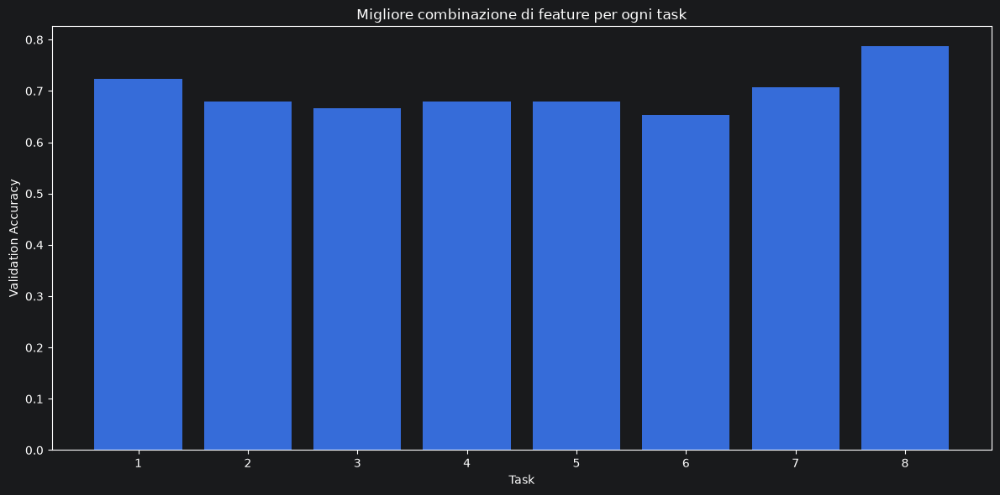

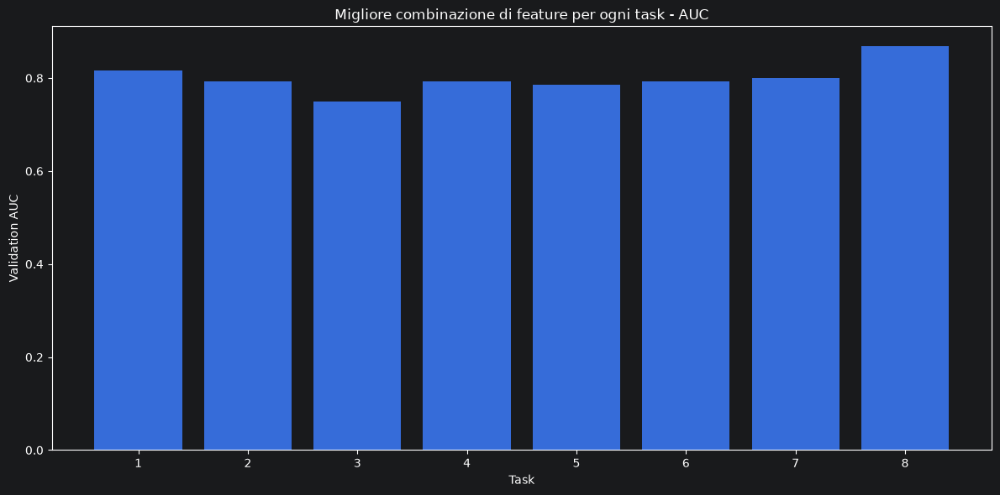

In [17]:
# ============================================================
# CNN1D - XY + TUTTE LE COMBINAZIONI DI FEATURE ENGINEERING
# ============================================================

import itertools

# ============================================================
# CONFIGURAZIONE
# ============================================================

tasks = [1, 2, 3, 4, 5, 6, 7, 8]

feature_eng = [
    "acceleration",
    "speed",
    "velocity",
    "pressure_derivative",
]

# Tutte le combinazioni non vuote
feature_combinations = []

for r in range(1, len(feature_eng) + 1):
    feature_combinations.extend(
        itertools.combinations(feature_eng, r)
    )

print(f"Numero di combinazioni: {len(feature_combinations)}")

for combo in feature_combinations:
    print(combo)

print(f"\nNumero totale di esperimenti: "
      f"{len(tasks) * len(feature_combinations)}")


# ============================================================
# ESPERIMENTI
# ============================================================

results = []

for t in tasks:

    for combo in feature_combinations:

        # Nome leggibile della configurazione
        feature_name = "_".join(combo)

        print("\n" + "=" * 80)
        print(f"Task: {t}")
        print(f"Feature: xy + {feature_name}")
        print("=" * 80)

        runner = RunSegmentCNN(
            data_root=_project_path(
                "PaHaW/PaHaW/PaHaW_public"
            ),

            metadata_path=_project_path(
                "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
            ),

            tasks=[t],

            # Feature originali
            feature_names=("x", "y"),

            # Combinazione corrente di feature engineering
            engineered_features=combo,

            # Iperparametri selezionati
            window_size=512,
            epochs=50,
            batch_size=16,
            learning_rate=1e-3,
            regularization=1e-4,
            n_splits=5,
            normalize=True,

            device=(
                "cuda"
                if torch.cuda.is_available()
                else "cpu"
            ),

            aggregation="mean",

            output_dir=_project_path(
                f"experiments/cnn1D/"
                f"raw_segment(train_seg - val_no)/"
                f"Task_{t}/xy_{feature_name}"
            ),

            training_cfg={
                "metrics": [
                    "accuracy",
                    "f1",
                    "auc",
                    "precision",
                    "recall",
                    "specificity",
                ],

                "monitor_metric": "auc",
                "early_stopping_patience": 50,
                "min_delta": 0.0,
                "results_writer": "csv",
                "save_metrics": True,
            },
        )

        summary = runner.run()

        averages = summary["averages"]

        results.append({
            "task": t,
            "feature": f"xy_{feature_name}",

            "accuracy": averages["val_accuracy"],
            "f1": averages["val_f1"],
            "auc": averages["val_auc"],
            "precision": averages["val_precision"],
            "recall": averages["val_recall"],
            "specificity": averages["val_specificity"],
        })


# ============================================================
# DATAFRAME
# ============================================================

df = pd.DataFrame(results)

df.to_csv(
    "cnn1d_xy_feature_combinations.csv",
    index=False
)

print("\n" + "=" * 80)
print("ESPERIMENTI COMPLETATI")
print("=" * 80)

print(f"Esperimenti eseguiti: {len(df)}")

display(df)


# ============================================================
# TOP ESPERIMENTI PER AUC
# ============================================================

df_sorted_auc = df.sort_values(
    by="auc",
    ascending=False
)

print("\n" + "=" * 80)
print("TOP 20 ESPERIMENTI - AUC")
print("=" * 80)

display(
    df_sorted_auc.head(20)
)


# ============================================================
# TOP ESPERIMENTI PER ACCURACY
# ============================================================

df_sorted_accuracy = df.sort_values(
    by="accuracy",
    ascending=False
)

print("\n" + "=" * 80)
print("TOP 20 ESPERIMENTI - ACCURACY")
print("=" * 80)

display(
    df_sorted_accuracy.head(20)
)


# ============================================================
# MIGLIORE FEATURE PER OGNI TASK
# ============================================================

best_per_task = (
    df
    .sort_values(
        ["task", "accuracy"],
        ascending=[True, False]
    )
    .groupby("task", as_index=False)
    .first()
)

print("\n" + "=" * 80)
print("MIGLIORE COMBINAZIONE PER OGNI TASK")
print("=" * 80)

display(
    best_per_task[
        [
            "task",
            "feature",
            "accuracy",
            "f1",
            "auc",
            "precision",
            "recall",
            "specificity",
        ]
    ]
)


# ============================================================
# PLOT - MIGLIORE ACCURACY PER TASK
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    best_per_task["task"].astype(str),
    best_per_task["accuracy"]
)

plt.xlabel("Task")
plt.ylabel("Validation Accuracy")
plt.title(
    "Migliore combinazione di feature per ogni task"
)

plt.tight_layout()
plt.show()


# ============================================================
# PLOT - MIGLIORE AUC PER TASK
# ============================================================

best_per_task_auc = (
    df
    .sort_values(
        ["task", "auc"],
        ascending=[True, False]
    )
    .groupby("task", as_index=False)
    .first()
)

plt.figure(figsize=(12, 6))

plt.bar(
    best_per_task_auc["task"].astype(str),
    best_per_task_auc["auc"]
)

plt.xlabel("Task")
plt.ylabel("Validation AUC")
plt.title(
    "Migliore combinazione di feature per ogni task - AUC"
)

plt.tight_layout()
plt.show()

In [ ]:
print(df_sorted_accuracy[
    ["task", "feature", "accuracy", "f1", "auc"]
].head(20).to_string(index=True))


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00005__2_1.svc: expected 1396, found 1344.
[WARNING] Mismatch in 00010__2_1.svc: expected 2114, found 2111.
[WARNING] Mismatch in 00051__5_1.svc: expected 1870, found 1620.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00005__2_1.svc: expected 1396, found 1344.
[WARNING] Mismatch in 00010__2_1.svc: expected 2114, found 2111.
[WARNING] Mismatch in 00051__5_1.svc: expected 1870, found 1620.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.7033 | train_accuracy=0.5099 | train_f1=0.6388 | train_auc=0.4669 | train_precision=0.5153 | train_recall=0.8401 | train_specificity=0.1579 | val_loss=0.6905 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.6071 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6928 | train_accuracy=0.5159 | train_f1=0.6806 | train_auc=0.4786 | train_pre

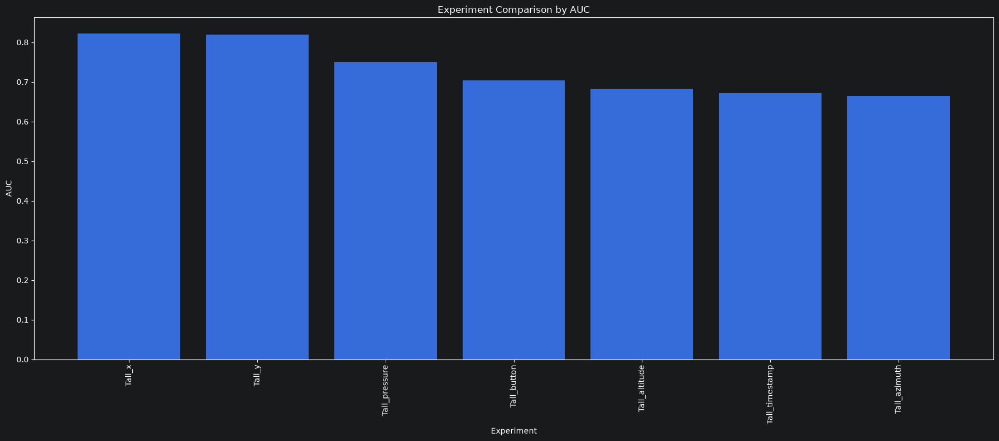

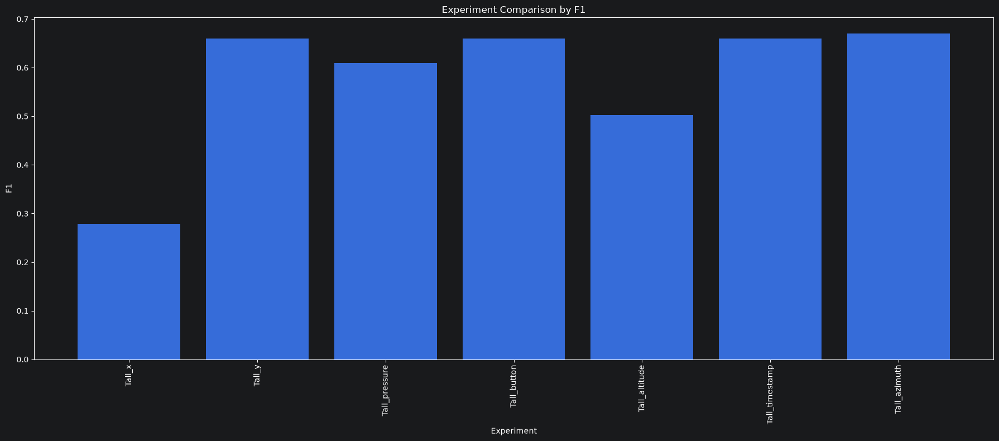


=== BEST EXPERIMENT ===
Task: all
Feature: x
AUC: 0.8214
F1: 0.2783
Accuracy: 0.5333


In [18]:
# Experiments for cnn1D (one feature -> all task)

features = ["x", "y", "button", "azimuth", "timestamp", "altitude", "pressure"]
results = []


for f in features:
    if f == "x" or f == "y":

        runner = RunSegmentCNN(
                data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
                metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
                tasks=[1, 2, 3, 4, 5, 6, 7, 8],
                feature_names=(f,),
                engineered_features=(),
                window_size=512,
                epochs=50,
                batch_size=16,
                learning_rate=1e-3,
                regularization=1e-4,
                n_splits=5,
                normalize=True,
                device="cuda" if torch.cuda.is_available() else "cpu",
                aggregation="mean",
                output_dir=_project_path(f"experiments/cnn1D/raw_segment(train_seg - val_no)/Task_all/{f}_coordinate"),
                training_cfg={
                    "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
                    "monitor_metric": "auc",
                    "early_stopping_patience": 50,
                    "min_delta": 0.0,
                    "results_writer": "csv",
                    "save_metrics": True,
                }
            )
    else:
        runner = RunSegmentCNN(
                data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
                metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
                tasks=[1, 2, 3, 4, 5, 6, 7, 8],
                feature_names=(f,),
                engineered_features=(),
                window_size=512,
                epochs=50,
                batch_size=16,
                learning_rate=1e-3,
                regularization=1e-4,
                n_splits=5,
                normalize=True,
                device="cuda" if torch.cuda.is_available() else "cpu",
                aggregation="mean",
                output_dir=_project_path(f"experiments/cnn1D/raw_segment(train_seg - val_no)/Task_all/{f}"),
                training_cfg={
                    "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
                    "monitor_metric": "auc",
                    "early_stopping_patience": 50,
                    "min_delta": 0.0,
                    "results_writer": "csv",
                    "save_metrics": True,
                }
            )

    summary = runner.run()

    averages = summary["averages"]

    results.append({
        "task": "all",
        "feature": f,
        "accuracy": averages["val_accuracy"],
        "f1": averages["val_f1"],
        "auc": averages["val_auc"],
        "precision": averages["val_precision"],
        "recall": averages["val_recall"],
        "specificity": averages["val_specificity"],
    })

# =========================
# DATAFRAME
# =========================

df = pd.DataFrame(results)

# Ordina per AUC
df_sorted = df.sort_values(by="auc", ascending=False)

print("\n=== TOP EXPERIMENTS ===")
print(df_sorted.head(10))

# =========================
# PLOT AUC
# =========================

labels = [
    f"T{row.task}_{row.feature}"
    for row in df_sorted.itertuples()
]

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["auc"])

plt.xticks(rotation=90)
plt.ylabel("AUC")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by AUC")

plt.tight_layout()
plt.show()

# =========================
# PLOT F1
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["f1"])

plt.xticks(rotation=90)
plt.ylabel("F1")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by F1")

plt.tight_layout()
plt.show()

# =========================
# BEST EXPERIMENT
# =========================

best = df_sorted.iloc[0]

print("\n=== BEST EXPERIMENT ===")
print(f"Task: {best['task']}")
print(f"Feature: {best['feature']}")
print(f"AUC: {best['auc']:.4f}")
print(f"F1: {best['f1']:.4f}")
print(f"Accuracy: {best['accuracy']:.4f}")


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00005__2_1.svc: expected 1396, found 1344.
[WARNING] Mismatch in 00010__2_1.svc: expected 2114, found 2111.
[WARNING] Mismatch in 00051__5_1.svc: expected 1870, found 1620.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00005__2_1.svc: expected 1396, found 1344.
[WARNING] Mismatch in 00010__2_1.svc: expected 2114, found 2111.
[WARNING] Mismatch in 00051__5_1.svc: expected 1870, found 1620.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.6981 | train_accuracy=0.5185 | train_f1=0.5957 | train_auc=0.5133 | train_precision=0.5254 | train_recall=0.6878 | train_specificity=0.3381 | val_loss=0.6905 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.5536 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6899 | train_accuracy=0.5515 | train_f1=0.5950 | train_auc=0.5696 | train_pre

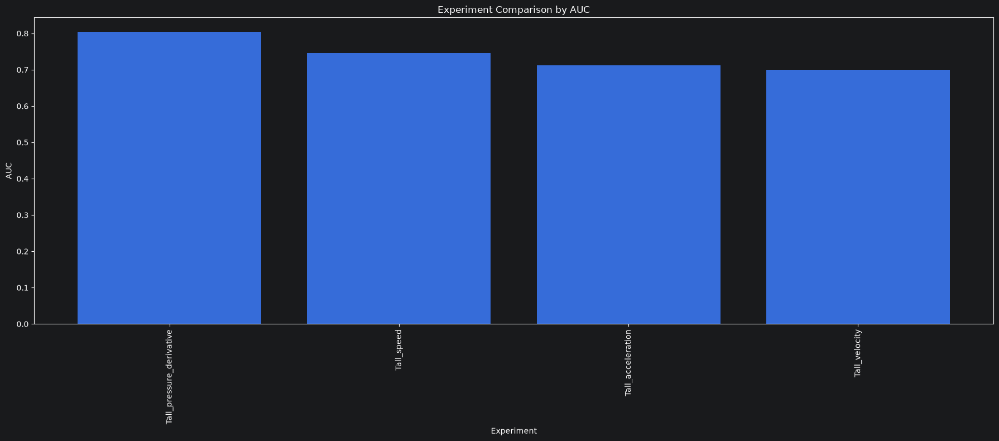

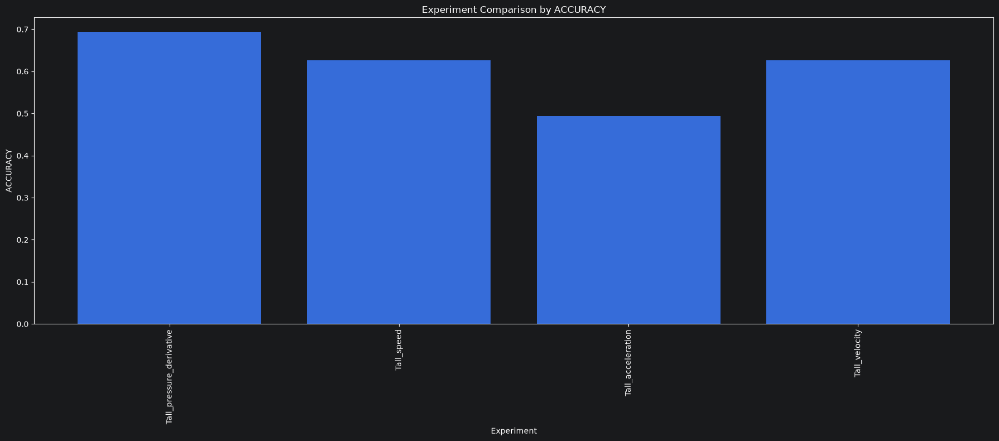

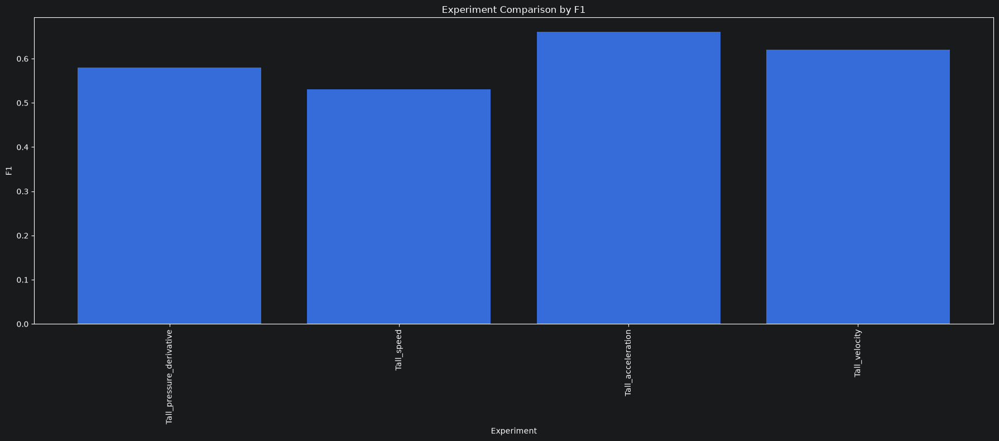


=== BEST EXPERIMENT ===
Task: all
Feature: pressure_derivative
AUC: 0.8036
F1: 0.5800
Accuracy: 0.6933


In [19]:
 # Experiments for cnn1D (one feature_eng -> all tasks)

feature = ["speed", "velocity", "acceleration", "pressure_derivative"]
results = []

for f in feature:

        runner = RunSegmentCNN(
                data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
                metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
                tasks=[1, 2, 3, 4, 5, 6, 7, 8],
                feature_names=(),
                engineered_features=(f,),
                window_size=512,
                epochs=50,
                batch_size=16,
                learning_rate=1e-3,
                regularization=1e-4,
                n_splits=5,
                normalize=True,
                device="cuda" if torch.cuda.is_available() else "cpu",
                aggregation="mean",
                output_dir=_project_path(f"experiments/cnn1D/raw_segment(train_seg - val_no)/Task_all/{f}"),
                training_cfg={
                    "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
                    "monitor_metric": "auc",
                    "early_stopping_patience": 50,
                    "min_delta": 0.0,
                    "results_writer": "csv",
                    "save_metrics": True,
                }
        )

        summary = runner.run()

        averages = summary["averages"]

        results.append({
            "task": "all",
            "feature": f,
            "accuracy": averages["val_accuracy"],
            "f1": averages["val_f1"],
            "auc": averages["val_auc"],
            "precision": averages["val_precision"],
            "recall": averages["val_recall"],
            "specificity": averages["val_specificity"],
        })

# =========================
# DATAFRAME
# =========================

df = pd.DataFrame(results)

# Ordina per AUC
df_sorted = df.sort_values(by="auc", ascending=False)

print("\n=== TOP EXPERIMENTS ===")
print(df_sorted.head(10))

# =========================
# PLOT AUC
# =========================

labels = [
    f"T{row.task}_{row.feature}"
    for row in df_sorted.itertuples()
]

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["auc"])

plt.xticks(rotation=90)
plt.ylabel("AUC")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by AUC")

plt.tight_layout()
plt.show()


# =========================
# PLOT ACCURACY
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["accuracy"])

plt.xticks(rotation=90)
plt.ylabel("ACCURACY")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by ACCURACY")

plt.tight_layout()
plt.show()
# =========================
# PLOT F1
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["f1"])

plt.xticks(rotation=90)
plt.ylabel("F1")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by F1")

plt.tight_layout()
plt.show()

# =========================
# BEST EXPERIMENT
# =========================

best = df_sorted.iloc[0]

print("\n=== BEST EXPERIMENT ===")
print(f"Task: {best['task']}")
print(f"Feature: {best['feature']}")
print(f"AUC: {best['auc']:.4f}")
print(f"F1: {best['f1']:.4f}")
print(f"Accuracy: {best['accuracy']:.4f}")

Fold 01 | Epoch 49 | train_loss=0.3992 | train_accuracy=0.8052 | train_f1=0.8076 | train_auc=0.8947 | train_precision=0.8324 | train_recall=0.7842 | train_specificity=0.8281 | val_loss=0.7074 | val_accuracy=0.8000 | val_f1=0.7692 | val_auc=0.7857 | val_precision=1.0000 | val_recall=0.6250 | val_specificity=1.0000
Fold 01 | Epoch 50 | train_loss=0.4230 | train_accuracy=0.7805 | train_f1=0.7838 | train_auc=0.8820 | train_precision=0.8056 | train_recall=0.7632 | train_specificity=0.7994 | val_loss=0.5881 | val_accuracy=0.8000 | val_f1=0.7692 | val_auc=0.8750 | val_precision=1.0000 | val_recall=0.6250 | val_specificity=1.0000
Fold 01 done | best_epoch=29 | val_loss=0.5517 | val_accuracy=0.8000

FOLD 02/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 02 | Epoch 01 | train_loss=0.6701 | train_accuracy=0.5979 | train_f1=0.6457 | train_auc=0.6242 | train_precision

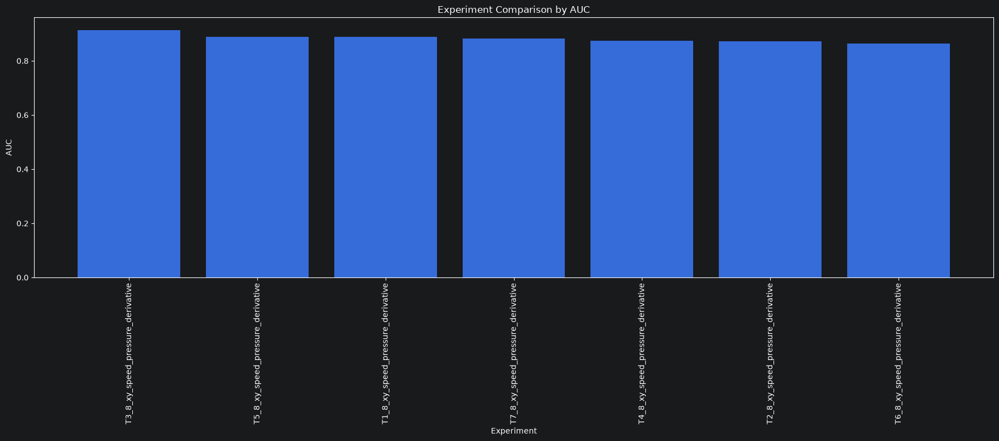

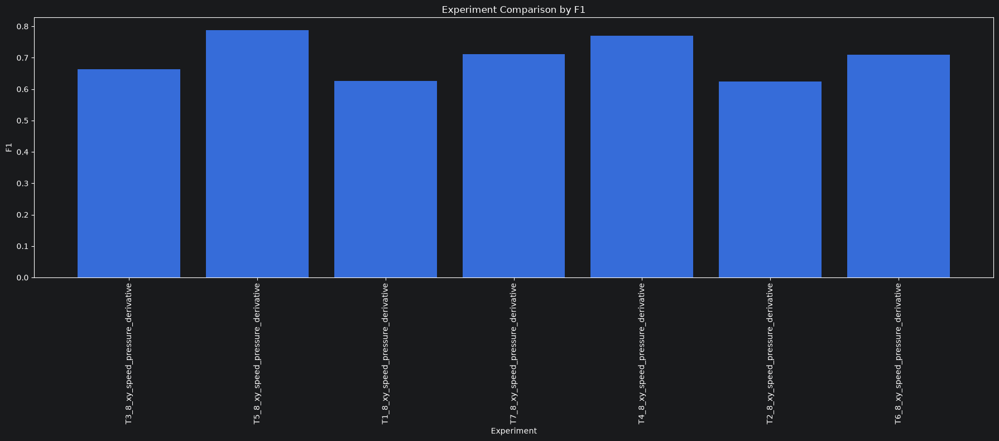


=== BEST EXPERIMENT ===
Task: 3_8
Feature: xy_speed_pressure_derivative
AUC: 0.9143
F1: 0.6629
Accuracy: 0.7467


In [23]:
 # Experiments for cnn1D

task = [1, 2, 3, 4, 5, 6, 7]
results = []

for t in task:

        runner = RunSegmentCNN(
                data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
                metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
                tasks=[t, 8],
                feature_names=("x", "y"),
                engineered_features=("speed","pressure_derivative"),
                window_size=512,
                epochs=50,
                batch_size=16,
                learning_rate=1e-3,
                regularization=1e-4,
                n_splits=5,
                normalize=True,
                device="cuda" if torch.cuda.is_available() else "cpu",
                aggregation="mean",
                output_dir=_project_path(f"experiments/cnn1D/raw_segment(train_seg - val_no)/Task_{t}_8/xy_speed_pressure_derivative"),
                training_cfg={
                    "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
                    "monitor_metric": "auc",
                    "early_stopping_patience": 50,
                    "min_delta": 0.0,
                    "results_writer": "csv",
                    "save_metrics": True,
                }
        )

        summary = runner.run()

        averages = summary["averages"]

        results.append({
            "task": f"{t}_8",
            "feature": "xy_speed_pressure_derivative",
            "accuracy": averages["val_accuracy"],
            "f1": averages["val_f1"],
            "auc": averages["val_auc"],
            "precision": averages["val_precision"],
            "recall": averages["val_recall"],
            "specificity": averages["val_specificity"],
        })

# =========================
# DATAFRAME
# =========================

df = pd.DataFrame(results)

# Ordina per AUC
df_sorted = df.sort_values(by="auc", ascending=False)

print("\n=== TOP EXPERIMENTS ===")
print(df_sorted.head(10))

# =========================
# PLOT AUC
# =========================

labels = [
    f"T{row.task}_{row.feature}"
    for row in df_sorted.itertuples()
]

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["auc"])

plt.xticks(rotation=90)
plt.ylabel("AUC")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by AUC")

plt.tight_layout()
plt.show()

# =========================
# PLOT F1
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["f1"])

plt.xticks(rotation=90)
plt.ylabel("F1")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by F1")

plt.tight_layout()
plt.show()

# =========================
# BEST EXPERIMENT
# =========================

best = df_sorted.iloc[0]

print("\n=== BEST EXPERIMENT ===")
print(f"Task: {best['task']}")
print(f"Feature: {best['feature']}")
print(f"AUC: {best['auc']:.4f}")
print(f"F1: {best['f1']:.4f}")
print(f"Accuracy: {best['accuracy']:.4f}")


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00005__2_1.svc: expected 1396, found 1344.
[WARNING] Mismatch in 00010__2_1.svc: expected 2114, found 2111.
[WARNING] Mismatch in 00051__5_1.svc: expected 1870, found 1620.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00005__2_1.svc: expected 1396, found 1344.
[WARNING] Mismatch in 00010__2_1.svc: expected 2114, found 2111.
[WARNING] Mismatch in 00051__5_1.svc: expected 1870, found 1620.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.6976 | train_accuracy=0.5060 | train_f1=0.6026 | train_auc=0.4885 | train_precision=0.5151 | train_recall=0.7261 | train_specificity=0.2715 | val_loss=0.6900 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.7679 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6899 | train_accuracy=0.5193 | train_f1=0.6583 | train_auc=0.5414 | train_pre

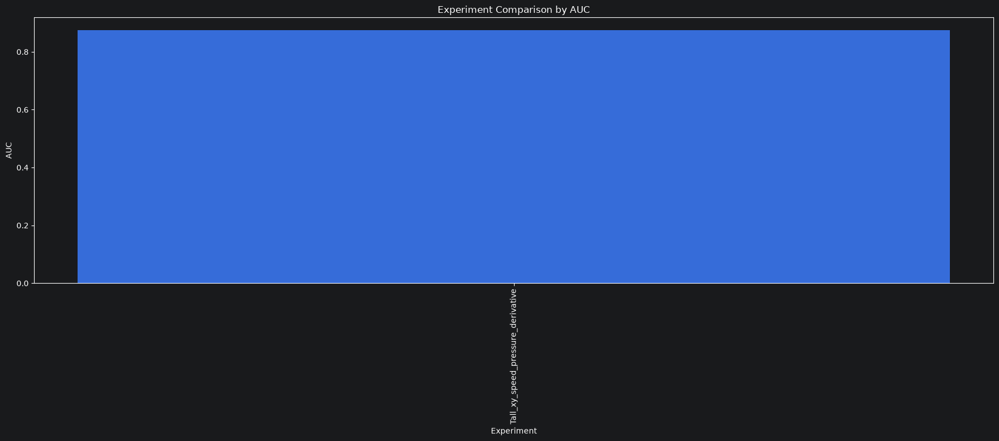

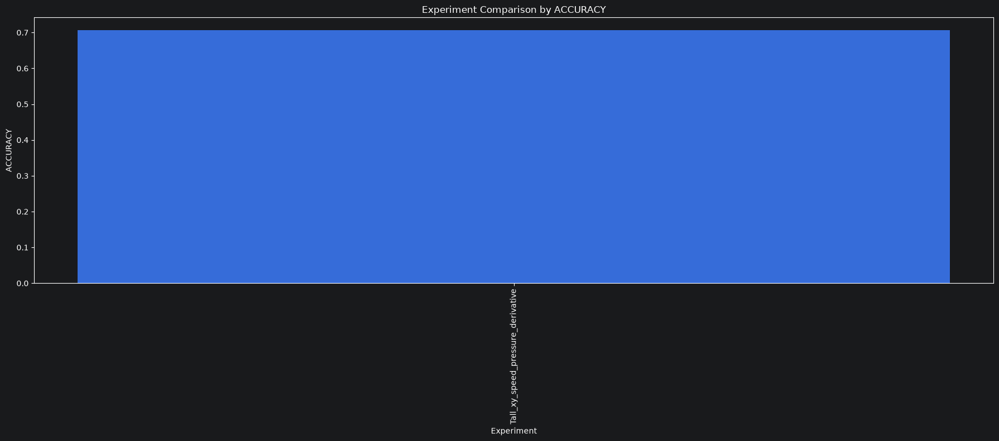

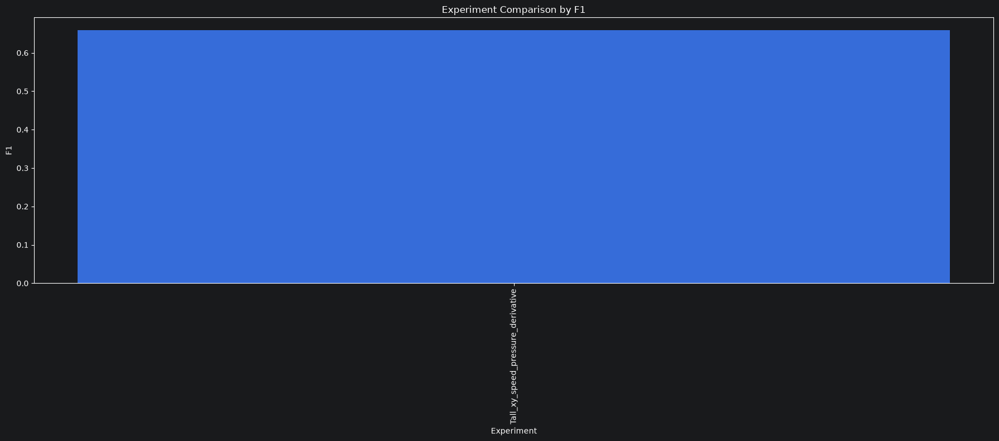


=== BEST EXPERIMENT ===
Task: all
Feature: xy_speed_pressure_derivative
AUC: 0.8750
F1: 0.6590
Accuracy: 0.7067


In [24]:
 # Experiments for cnn1D

results = []

runner = RunSegmentCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
        tasks=[1, 2, 3, 4, 5, 6, 7, 8],
         feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative"),
        window_size=512,
        epochs=50,
        batch_size=16,
        learning_rate=1e-3,
        regularization=1e-4,
        n_splits=5,
        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",
        aggregation="mean",
        output_dir=_project_path(f"experiments/cnn1D/raw_segment(train_seg - val_no)/Task_all/xy_speed_pressure_derivative"),
        training_cfg={
            "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
            "monitor_metric": "auc",
            "early_stopping_patience": 50,
            "min_delta": 0.0,
            "results_writer": "csv",
            "save_metrics": True,
        }
)

summary = runner.run()

averages = summary["averages"]

results.append({
    "task": "all",
    "feature": "xy_speed_pressure_derivative",
    "accuracy": averages["val_accuracy"],
    "f1": averages["val_f1"],
    "auc": averages["val_auc"],
    "precision": averages["val_precision"],
    "recall": averages["val_recall"],
    "specificity": averages["val_specificity"],
})

# =========================
# DATAFRAME
# =========================

df = pd.DataFrame(results)

# Ordina per AUC
df_sorted = df.sort_values(by="auc", ascending=False)

print("\n=== TOP EXPERIMENTS ===")
print(df_sorted.head(10))

# =========================
# PLOT AUC
# =========================

labels = [
    f"T{row.task}_{row.feature}"
    for row in df_sorted.itertuples()
]

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["auc"])

plt.xticks(rotation=90)
plt.ylabel("AUC")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by AUC")

plt.tight_layout()
plt.show()


# =========================
# PLOT ACCURACY
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["accuracy"])

plt.xticks(rotation=90)
plt.ylabel("ACCURACY")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by ACCURACY")

plt.tight_layout()
plt.show()
# =========================
# PLOT F1
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["f1"])

plt.xticks(rotation=90)
plt.ylabel("F1")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by F1")

plt.tight_layout()
plt.show()

# =========================
# BEST EXPERIMENT
# =========================

best = df_sorted.iloc[0]

print("\n=== BEST EXPERIMENT ===")
print(f"Task: {best['task']}")
print(f"Feature: {best['feature']}")
print(f"AUC: {best['auc']:.4f}")
print(f"F1: {best['f1']:.4f}")
print(f"Accuracy: {best['accuracy']:.4f}")


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.6293 | train_accuracy=0.6615 | train_f1=0.6632 | train_auc=0.7146 | train_precision=0.6667 | train_recall=0.6598 | train_specificity=0.6632 | val_loss=0.4914 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8571 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 02 | train_loss=0.5835 | train_accuracy=0.7318 | train_f1=0.7253 | train_auc=0.7563 | train_precision=0.7514 | train_recall=0.7010 | train_specificity=0.7632 | val_loss=0.5084 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8929 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 03 | train_loss=0.6036 | train_accuracy=0.7396 | train_f1=0.7297 | train_auc=0.7274 | train_precision=0.7670 | train_recall=0.6959 | train_specificity=0.7842 | val_loss=0

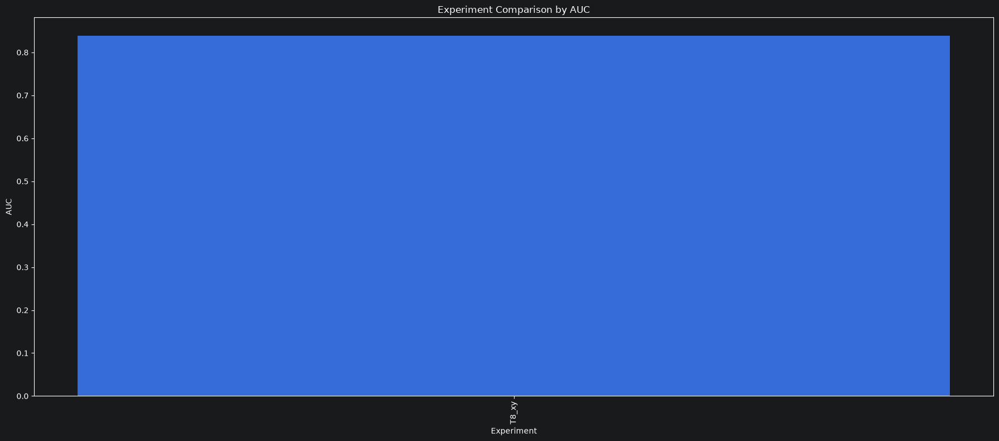

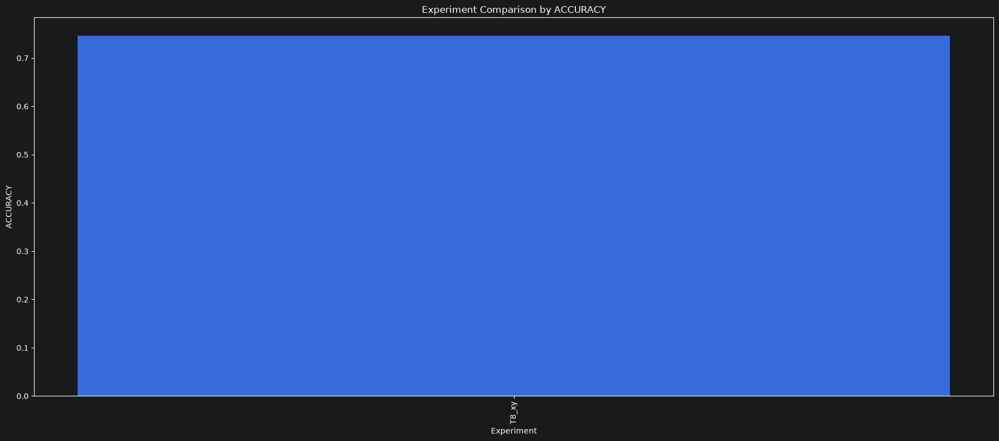

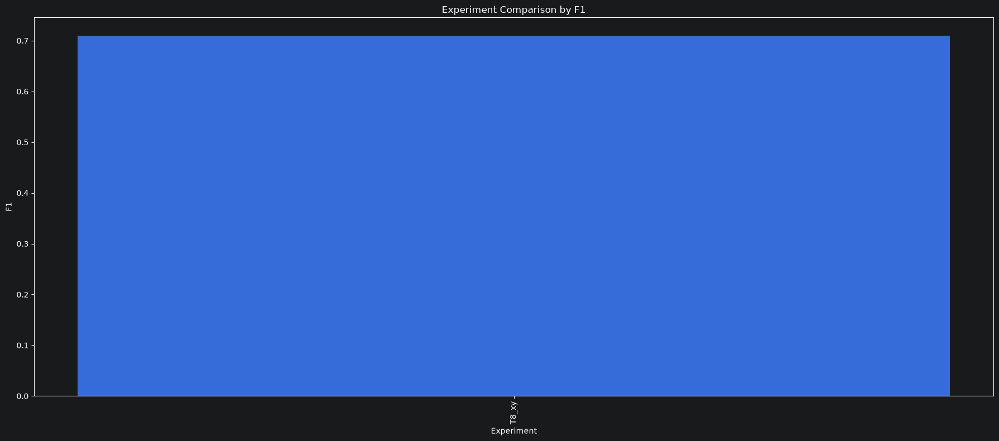


=== BEST EXPERIMENT ===
Task: 8
Feature: xy
AUC: 0.8393
F1: 0.7100
Accuracy: 0.7467


In [25]:
 # Experiments for cnn1D

results = []
tasks = [1,2,3,4,5,6,7,8]

for t in tasks:

    runner = RunSegmentCNN(
            data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
            metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
            tasks=[t],
             feature_names=("x", "y"),
            engineered_features=(),
            window_size=512,
            epochs=50,
            batch_size=16,
            learning_rate=1e-3,
            regularization=1e-4,
            n_splits=5,
            normalize=True,
            device="cuda" if torch.cuda.is_available() else "cpu",
            aggregation="mean",
            output_dir=_project_path(f"experiments/cnn1D/raw_segment(train_seg - val_no)/Task_all/xy_coordinate"),
            training_cfg={
                "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
                "monitor_metric": "auc",
                "early_stopping_patience": 50,
                "min_delta": 0.0,
                "results_writer": "csv",
                "save_metrics": True,
            }
    )

summary = runner.run()

averages = summary["averages"]

results.append({
    "task": t,
    "feature": "xy",
    "accuracy": averages["val_accuracy"],
    "f1": averages["val_f1"],
    "auc": averages["val_auc"],
    "precision": averages["val_precision"],
    "recall": averages["val_recall"],
    "specificity": averages["val_specificity"],
})

# =========================
# DATAFRAME
# =========================

df = pd.DataFrame(results)

# Ordina per AUC
df_sorted = df.sort_values(by="auc", ascending=False)

print("\n=== TOP EXPERIMENTS ===")
print(df_sorted.head(10))

# =========================
# PLOT AUC
# =========================

labels = [
    f"T{row.task}_{row.feature}"
    for row in df_sorted.itertuples()
]

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["auc"])

plt.xticks(rotation=90)
plt.ylabel("AUC")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by AUC")

plt.tight_layout()
plt.show()


# =========================
# PLOT ACCURACY
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["accuracy"])

plt.xticks(rotation=90)
plt.ylabel("ACCURACY")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by ACCURACY")

plt.tight_layout()
plt.show()
# =========================
# PLOT F1
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["f1"])

plt.xticks(rotation=90)
plt.ylabel("F1")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by F1")

plt.tight_layout()
plt.show()

# =========================
# BEST EXPERIMENT
# =========================

best = df_sorted.iloc[0]

print("\n=== BEST EXPERIMENT ===")
print(f"Task: {best['task']}")
print(f"Feature: {best['feature']}")
print(f"AUC: {best['auc']:.4f}")
print(f"F1: {best['f1']:.4f}")
print(f"Accuracy: {best['accuracy']:.4f}")